In [1]:
# importation des bibliothéques
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [12]:
# Charger les fichiers depuis ton dossier "wine+quality"
path_red = '/content/drive/MyDrive/wine+quality/winequality-red.csv'
path_white = '/content/drive/MyDrive/wine+quality/winequality-white.csv'

df_red = pd.read_csv(path_red, sep=';')
df_white = pd.read_csv(path_white, sep=';')

In [13]:
# Ajouter la colonne 'type' et fusionner
df_red['type'] = 'rouge'
df_white['type'] = 'blanc'
df = pd.concat([df_red, df_white], ignore_index=True)

In [15]:
# Vérifier les dimensions et afficher les premières lignes
print("Dimensions du dataset fusionné :", df.shape)
display(df.head(10))

Dimensions du dataset fusionné : (6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,rouge
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,rouge
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,rouge
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,rouge
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,rouge
5,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5,rouge
6,7.9,0.60,0.06,1.6,0.069,15.0,59.0,0.9964,3.30,0.46,9.4,5,rouge
7,7.3,0.65,0.00,1.2,0.065,15.0,21.0,0.9946,3.39,0.47,10.0,7,rouge
8,7.8,0.58,0.02,2.0,0.073,9.0,18.0,0.9968,3.36,0.57,9.5,7,rouge
9,7.5,0.50,0.36,6.1,0.071,17.0,102.0,0.9978,3.35,0.80,10.5,5,rouge


In [18]:
print("Nombre total de lignes :", len(df))
print(df['type'].value_counts())

Nombre total de lignes : 6497
type
blanc    4898
rouge    1599
Name: count, dtype: int64


In [20]:
#  Vérification des valeurs manquantes par colonne
print("--- 1. VALEURS MANQUANTES ---")
print(df.isnull().sum())
print("\nNombre total de valeurs manquantes dans tout le dataset :", df.isnull().sum().sum())

#  Vérification du nombre de doublons avant nettoyage
print("\n--- 2. GESTION DES DOUBLONS ---")
print("Nombre de lignes en double détectées :", df.duplicated().sum())

#  Suppression des doublons
df = df.drop_duplicates().reset_index(drop=True)

#  Affichage des dimensions après nettoyage
print("\n--- 3. DIMENSIONS FINALES APRÈS NETTOYAGE ---")
print("Nouvelles dimensions du dataset :", df.shape)

#  Aperçu rapide des statistiques descriptives de base
display(df.describe())

--- 1. VALEURS MANQUANTES ---
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
type                    0
dtype: int64

Nombre total de valeurs manquantes dans tout le dataset : 0

--- 2. GESTION DES DOUBLONS ---
Nombre de lignes en double détectées : 1177

--- 3. DIMENSIONS FINALES APRÈS NETTOYAGE ---
Nouvelles dimensions du dataset : (5320, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,5320.000000,5320.000000,5320.000000,5320.000000,5320.000000,5320.000000,5320.000000,5320.000000,5320.000000,5320.000000,5320.000000,5320.000000
mean,7.215179,0.344130,0.318494,5.048477,0.056690,30.036654,114.109023,0.994535,3.224664,0.533357,10.549241,5.795677
std,1.319671,0.168248,0.147157,4.500180,0.036863,17.805045,56.774223,0.002966,0.160379,0.149743,1.185933,0.879772
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.400000,0.230000,0.240000,1.800000,0.038000,16.000000,74.000000,0.992200,3.110000,0.430000,9.500000,5.000000
50%,7.000000,0.300000,0.310000,2.700000,0.047000,28.000000,116.000000,0.994650,3.210000,0.510000,10.400000,6.000000
75%,7.700000,0.410000,0.400000,7.500000,0.066000,41.000000,153.250000,0.996770,3.330000,0.600000,11.400000,6.000000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000,9.000000


In [22]:


# Séparation des caractéristiques (les 11 variables chimiques) et des variables qualitatives (qualité et type)
X = df.drop(columns=['quality', 'type'])
y_quality = df['quality']
y_type = df['type']

# Affichage des colonnes retenues pour l'ACP
print("Variables chimiques prises en compte pour l'ACP :")
print(list(X.columns))

#  Centrage-Réduction des données (Standardisation)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Vérification de la transformation (la moyenne doit être proche de 0 et l'écart-type de 1)
import numpy as np
print("\nMoyenne après scaling (doit être ~0) :", np.round(X_scaled.mean(), 5))
print("Écart-type après scaling (doit être 1) :", np.round(X_scaled.std(), 2))

Variables chimiques prises en compte pour l'ACP :
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']

Moyenne après scaling (doit être ~0) : 0.0
Écart-type après scaling (doit être 1) : 1.0


In [24]:


#  Application de l'ACP sur toutes les composantes possibles (11 dimensions)
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

# Calcul du pourcentage de variance expliquée par chaque axe
variance_expliquee = pca.explained_variance_ratio_ * 100
variance_cumulee = variance_expliquee.cumsum()

# Affichage du tableau récapitulatif
df_variance = pd.DataFrame({
    'Composante': [f'CP{i+1}' for i in range(len(variance_expliquee))],
    'Variance Expliquée (%)': variance_expliquee,
    'Variance Cumulée (%)': variance_cumulee
})

display(df_variance)

,Composante,Variance Expliquée (%),Variance Cumulée (%)
0,CP1,27.167050,27.167050
1,CP2,22.502425,49.669476
2,CP3,14.429840,64.099315
3,CP4,8.667287,72.766602
4,CP5,6.747594,79.514196
5,CP6,5.700345,85.214541
6,CP7,4.736727,89.951268
7,CP8,4.614532,94.565801
8,CP9,3.061100,97.626900
9,CP10,2.054165,99.681066


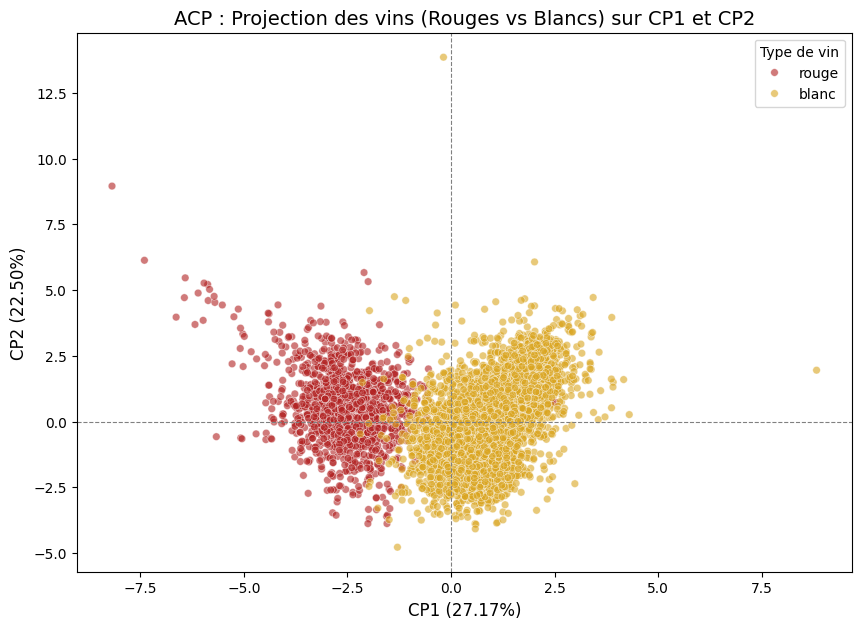

In [25]:

# Création d'un DataFrame pour le graphique
df_pca = pd.DataFrame(X_pca[:, :2], columns=['CP1', 'CP2'])
df_pca['type'] = df['type'].values
df_pca['quality'] = df['quality'].values

# Tracé du graphique 2D avec Seaborn
plt.figure(figsize=(10, 7))
sns.scatterplot(
    x='CP1', y='CP2',
    hue='type',
    palette={'rouge': 'firebrick', 'blanc': 'goldenrod'},
    data=df_pca,
    alpha=0.6,
    s=30
)

plt.title('ACP : Projection des vins (Rouges vs Blancs) sur CP1 et CP2', fontsize=14)
plt.xlabel(f'CP1 ({variance_expliquee[0]:.2f}%)', fontsize=12)
plt.ylabel(f'CP2 ({variance_expliquee[1]:.2f}%)', fontsize=12)
plt.axhline(0, color='grey', linestyle='--', linewidth=0.8)
plt.axvline(0, color='grey', linestyle='--', linewidth=0.8)
plt.legend(title='Type de vin')
plt.show()

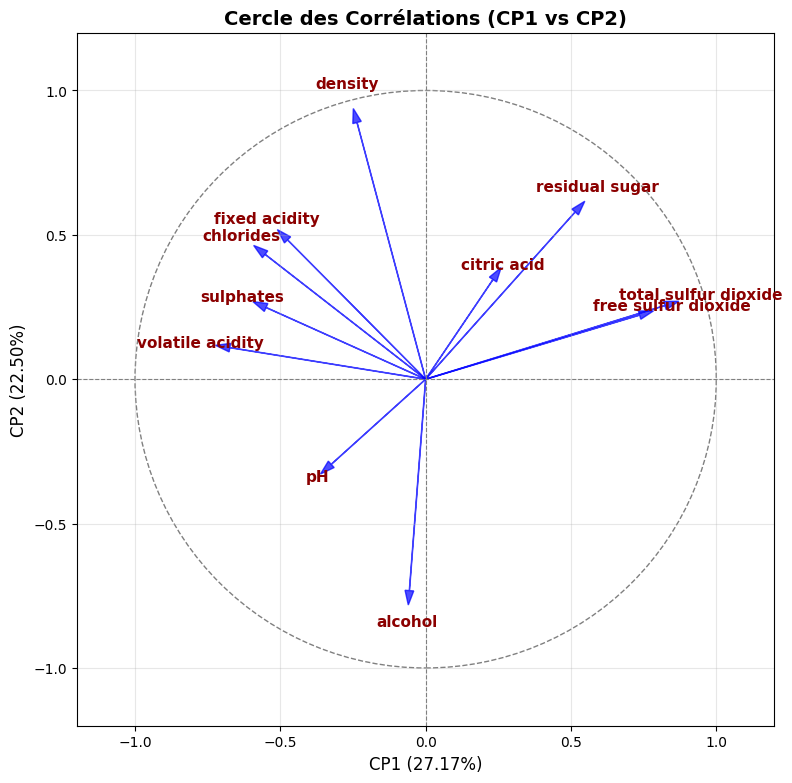

In [27]:


#  Calcul des corrélations entre les variables initiales et les composantes principales
loadings = pca.components_[:2, :].T * np.sqrt(pca.explained_variance_[:2])

# Création du graphique
plt.figure(figsize=(9, 9))
plt.axhline(0, color='grey', linestyle='--', linewidth=0.8)
plt.axvline(0, color='grey', linestyle='--', linewidth=0.8)

# Tracé des flèches et des étiquettes (version corrigée)
for i, feature in enumerate(X.columns):
    plt.arrow(0, 0, loadings[i, 0], loadings[i, 1],
              color='b', alpha=0.7, head_width=0.03, head_length=0.05)
    plt.text(loadings[i, 0] * 1.15, loadings[i, 1] * 1.15, feature,
             color='darkred', ha='center', va='center', fontsize=11, weight='bold')

# Dessin du cercle unitaire (rayon = 1)
circle = plt.Circle((0, 0), 1, color='gray', fill=False, linestyle='--', linewidth=1)
plt.gca().add_patch(circle)

# Configuration des axes et du titre
plt.xlim(-1.2, 1.2)
plt.ylim(-1.2, 1.2)
plt.title('Cercle des Corrélations (CP1 vs CP2)', fontsize=14, weight='bold')
plt.xlabel(f'CP1 ({variance_expliquee[0]:.2f}%)', fontsize=12)
plt.ylabel(f'CP2 ({variance_expliquee[1]:.2f}%)', fontsize=12)
plt.grid(True, alpha=0.3)
plt.show()

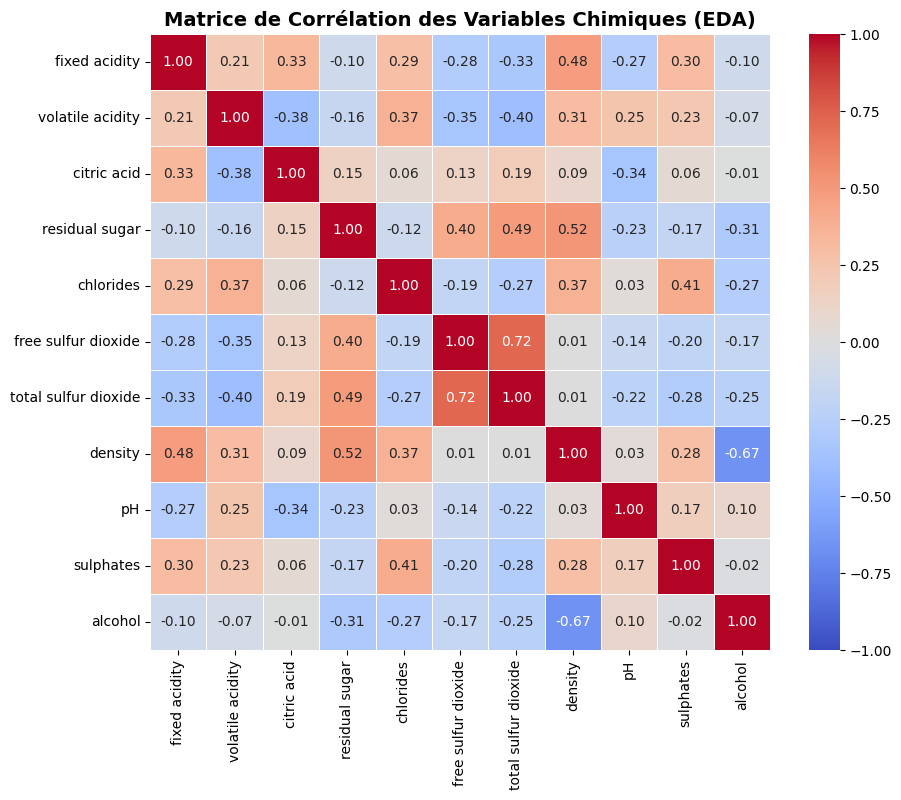

In [28]:

plt.figure(figsize=(10, 8))
# Calcul de la matrice de corrélation sur les 11 variables chimiques
corr_matrix = X.corr()

# Tracé de la heatmap
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Matrice de Corrélation des Variables Chimiques (EDA)', fontsize=14, weight='bold')
plt.show()

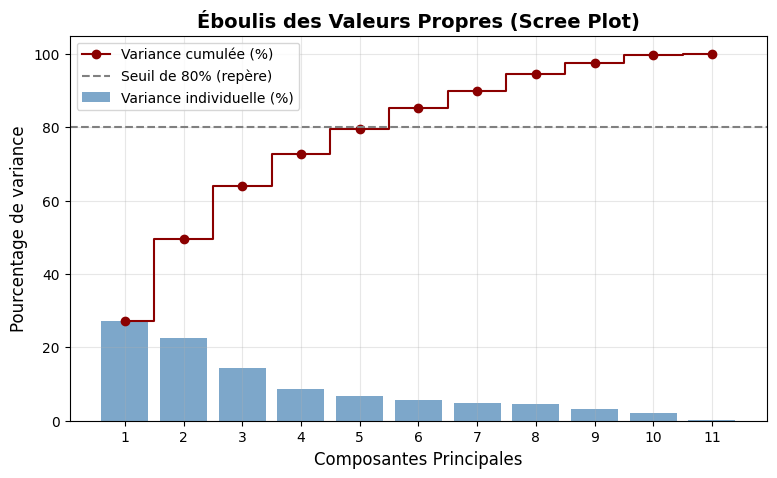

In [29]:
plt.figure(figsize=(9, 5))

# Histogramme de la variance expliquée par chaque composante
plt.bar(range(1, len(variance_expliquee) + 1), variance_expliquee, alpha=0.7, color='steelblue', label='Variance individuelle (%)')
# Courbe de la variance cumulée
plt.step(range(1, len(variance_cumulee) + 1), variance_cumulee, where='mid', color='darkred', marker='o', label='Variance cumulée (%)')

plt.axhline(y=80, color='grey', linestyle='--', label='Seuil de 80% (repère)')
plt.xlabel('Composantes Principales', fontsize=12)
plt.ylabel('Pourcentage de variance', fontsize=12)
plt.title('Éboulis des Valeurs Propres (Scree Plot)', fontsize=14, weight='bold')
plt.xticks(range(1, len(variance_expliquee) + 1))
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.show()